# 2. Image Compression

Practice for week 2: entropy, a Huffman coder written from scratch, lossless predictive coding, and a
JPEG-style pipeline (8×8 blocks → DCT → quantization) with the rate–distortion trade-off. Also a check of
why JPEG uses the DCT and not the Fourier transform.

In [1]:
import heapq, itertools
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
plt.rcParams["figure.dpi"] = 80
rng = np.random.default_rng(0)

def make_image(n=256):
    y, x = np.mgrid[:n, :n] / n
    img = 0.25 + 0.4 * x + 0.1 * np.sin(6 * np.pi * y)
    img[(x - 0.3) ** 2 + (y - 0.35) ** 2 < 0.04] = 0.9
    img[(x > 0.55) & (x < 0.9) & (y > 0.55) & (y < 0.85)] = 0.15
    s = (y > 0.7) & (x < 0.45)
    img[s] = 0.5 + 0.3 * np.sign(np.sin(2 * np.pi * 40 * x[s]))
    return img.clip(0, 1)

def entropy(values):
    _, counts = np.unique(values, return_counts=True)
    p = counts / counts.sum()
    return -(p * np.log2(p)).sum()

def psnr(a, b, peak=255.0):
    return 10 * np.log10(peak ** 2 / np.mean((a - b) ** 2))

img8 = np.round(make_image() * 255 + rng.normal(0, 2, (256, 256))).clip(0, 255)   # a little sensor noise

## 2.1 Entropy and variable-length coding

Entropy is the lower bound on bits per symbol. If all 8 gray levels are equally likely, entropy is
already 3 bits, the same as a fixed 3-bit code, so variable-length coding gains nothing.

In [2]:
uniform = rng.integers(0, 8, 100_000)
skewed = rng.choice(8, 100_000, p=[0.5, 0.2, 0.1, 0.08, 0.05, 0.04, 0.02, 0.01])
print(f"uniform 8 levels: entropy {entropy(uniform):.3f} bits (fixed code: 3)")
print(f"skewed 8 levels : entropy {entropy(skewed):.3f} bits (fixed code: 3)")

uniform 8 levels: entropy 3.000 bits (fixed code: 3)
skewed 8 levels : entropy 2.166 bits (fixed code: 3)


## 2.2 Huffman coding

Repeatedly merge the two least probable nodes. The code is not unique: ties can be broken differently
and 0/1 can be swapped, but every Huffman code has the same (optimal) average length.

In [3]:
def huffman(probs, order=None):
    cnt = itertools.count()
    heap = [(p, next(cnt), {s: ""}) for s, p in (order or list(probs.items()))]
    heapq.heapify(heap)
    while len(heap) > 1:
        p1, _, c1 = heapq.heappop(heap); p2, _, c2 = heapq.heappop(heap)
        merged = {s: "0" + c for s, c in c1.items()} | {s: "1" + c for s, c in c2.items()}
        heapq.heappush(heap, (p1 + p2, next(cnt), merged))
    return heap[0][2]

probs = {"a": 3 / 8, "b": 1 / 8, "c": 1 / 8, "d": 3 / 8}
H = -sum(p * np.log2(p) for p in probs.values())
for name, order in [("ties: a first", list(probs.items())), ("ties: d first", list(probs.items())[::-1])]:
    code = huffman(probs, order)
    avg = sum(probs[s] * len(c) for s, c in code.items())
    print(f"{name}: {dict(sorted(code.items()))}  average {avg:.3f} bits (entropy {H:.3f})")

ties: a first: {'a': '11', 'b': '100', 'c': '101', 'd': '0'}  average 1.875 bits (entropy 1.811)
ties: d first: {'a': '0', 'b': '101', 'c': '100', 'd': '11'}  average 1.875 bits (entropy 1.811)


In [4]:
vals, counts = np.unique(img8, return_counts=True)
code = huffman(dict(zip(vals, counts / counts.sum())))
bits = sum(c * len(code[v]) for v, c in zip(vals, counts)) / img8.size
print(f"Huffman on the test image: {bits:.3f} bits/pixel (entropy {entropy(img8):.3f}, raw 8)")

Huffman on the test image: 7.227 bits/pixel (entropy 7.191, raw 8)


## 2.3 Lossless predictive coding

Predict each pixel from its left neighbour (already decoded, so the decoder can make the same prediction)
and code only the error. The error histogram is sharply peaked at 0, so its entropy is much lower.
Decoding is a cumulative sum and gives back the image exactly.

entropy: pixels 7.191 bits, prediction error 3.945 bits
lossless reconstruction: True


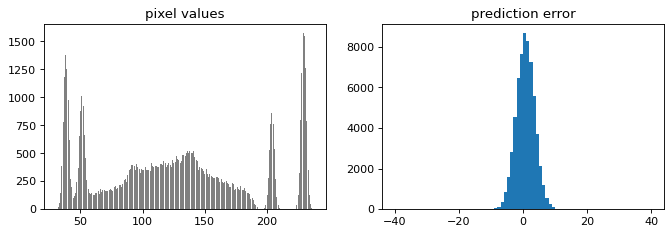

In [5]:
err = img8.copy()
err[:, 1:] = img8[:, 1:] - img8[:, :-1]
decoded = np.cumsum(err, axis=1)
print(f"entropy: pixels {entropy(img8):.3f} bits, prediction error {entropy(err[:, 1:]):.3f} bits")
print("lossless reconstruction:", np.array_equal(decoded, img8))

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].hist(img8.ravel(), 256, color="gray"); axes[0].set_title("pixel values")
axes[1].hist(err[:, 1:].ravel(), np.arange(-40, 41), color="tab:blue"); axes[1].set_title("prediction error")
plt.show()

## 2.4 JPEG-style compression

Split into 8×8 blocks, apply the 2D DCT, divide by the standard luminance quantization table (times a
scale factor), round, and estimate the rate by the entropy of the quantized coefficients. Rounding in the
quantizer is the only lossy step: without it, DCT and inverse DCT reproduce the block exactly.

In [6]:
C = np.array([[np.sqrt((1 if k == 0 else 2) / 8) * np.cos((2 * n + 1) * k * np.pi / 16) for n in range(8)] for k in range(8)])
Q = np.array([[16, 11, 10, 16, 24, 40, 51, 61], [12, 12, 14, 19, 26, 58, 60, 55],
              [14, 13, 16, 24, 40, 57, 69, 56], [14, 17, 22, 29, 51, 87, 80, 62],
              [18, 22, 37, 56, 68, 109, 103, 77], [24, 35, 55, 64, 81, 104, 113, 92],
              [49, 64, 78, 87, 103, 121, 120, 101], [72, 92, 95, 98, 112, 100, 103, 99]], float)

to_blocks = lambda u: u.reshape(32, 8, 32, 8).transpose(0, 2, 1, 3)
from_blocks = lambda b: b.transpose(0, 2, 1, 3).reshape(256, 256)

def jpeg(u, scale):
    coef = C @ to_blocks(u - 128) @ C.T
    q = np.round(coef / (Q * scale))
    rec = from_blocks(C.T @ (q * Q * scale) @ C) + 128
    return rec.clip(0, 255), entropy(q)

print("DCT -> inverse DCT without quantization, max error:", np.abs(from_blocks(C.T @ (C @ to_blocks(img8) @ C.T) @ C) - img8).max().round(10))
scales = [0.25, 0.5, 1, 2, 4, 8, 16]
results = [jpeg(img8, s) for s in scales]
for s, (rec, bpp) in zip(scales, results):
    print(f"scale {s:5.2f}: ~{bpp:.2f} bits/pixel, ratio {8 / bpp:5.1f}:1, PSNR {psnr(rec, img8):.1f} dB")

DCT -> inverse DCT without quantization, max error: 0.0
scale  0.25: ~1.37 bits/pixel, ratio   5.8:1, PSNR 41.8 dB
scale  0.50: ~0.91 bits/pixel, ratio   8.8:1, PSNR 39.1 dB
scale  1.00: ~0.66 bits/pixel, ratio  12.1:1, PSNR 36.3 dB
scale  2.00: ~0.49 bits/pixel, ratio  16.3:1, PSNR 32.8 dB
scale  4.00: ~0.38 bits/pixel, ratio  20.9:1, PSNR 30.2 dB
scale  8.00: ~0.26 bits/pixel, ratio  30.7:1, PSNR 25.9 dB
scale 16.00: ~0.19 bits/pixel, ratio  42.0:1, PSNR 23.6 dB


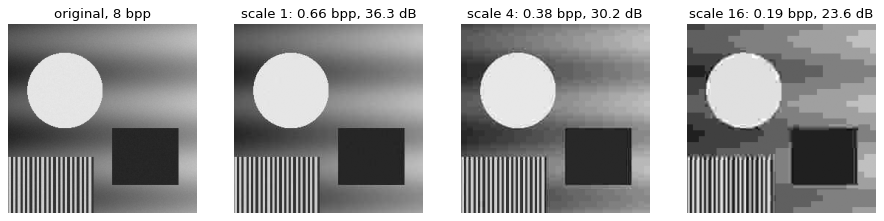

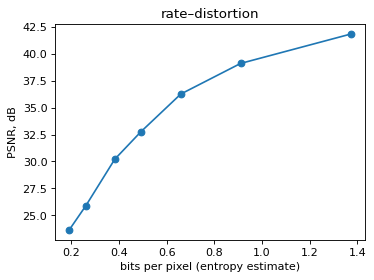

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8))
axes[0].imshow(img8, cmap="gray", vmin=0, vmax=255); axes[0].set_title("original, 8 bpp")
for a, i in zip(axes[1:], [2, 4, 6]):
    rec, bpp = results[i]
    a.imshow(rec, cmap="gray", vmin=0, vmax=255); a.set_title(f"scale {scales[i]}: {bpp:.2f} bpp, {psnr(rec, img8):.1f} dB")
for a in axes: a.axis("off")
plt.show()

plt.figure(figsize=(5, 3.5))
plt.plot([b for _, b in results], [psnr(r, img8) for r, _ in results], "o-")
plt.xlabel("bits per pixel (entropy estimate)"); plt.ylabel("PSNR, dB"); plt.title("rate–distortion")
plt.show()

Doubling the quantization step does not halve the bit rate, and at large steps the rate drops well below
1 bit per pixel, so the compression ratio is not capped at 8:1.

## 2.5 Why the DCT and not the DFT

Keep only the k largest coefficients of every 8×8 block and reconstruct. The DFT treats the block as
periodic, so the jump between opposite edges spreads energy over many coefficients; the DCT (an even
extension) has no such jump and also gives real-valued coefficients.

In [8]:
blocks = to_blocks(img8 - 128).reshape(-1, 8, 8)
for k in [1, 3, 6, 10]:
    errs = []
    for name in ["DCT", "DFT"]:
        F = C @ blocks @ C.T if name == "DCT" else np.fft.fft2(blocks)
        thr = -np.sort(-np.abs(F).reshape(len(F), -1), axis=1)[:, k - 1]
        Fk = np.where(np.abs(F) >= thr[:, None, None], F, 0)
        rec = C.T @ Fk @ C if name == "DCT" else np.fft.ifft2(Fk).real
        errs.append(np.sqrt(np.mean((rec - blocks) ** 2)))
    print(f"keep {k:2d} of 64 coefficients: RMSE DCT {errs[0]:.2f}, DFT {errs[1]:.2f}")

keep  1 of 64 coefficients: RMSE DCT 20.89, DFT 23.27
keep  3 of 64 coefficients: RMSE DCT 12.99, DFT 17.53
keep  6 of 64 coefficients: RMSE DCT 6.53, DFT 9.02
keep 10 of 64 coefficients: RMSE DCT 4.46, DFT 6.63
